# Model Evaluation and Business Insights

## Customer Intelligence Platform V2

### Objective

Evaluate the reliability, temporal stability and practical business implications of the selected repeat-purchase prediction model.

The selected model is an unweighted Logistic Regression pipeline trained using nine customer features derived from first-order purchasing information.

### Evaluation Framework

**1. Probability Calibration**

Assess whether predicted repeat-purchase probabilities reflect observed customer outcomes.

**2. Temporal Stability**

Evaluate how model performance changes across historical validation months and investigate possible explanations for those differences.

**3. Final Model Assessment**

Review ranking quality, probability reliability, modelling assumptions and limitations before final holdout evaluation.

**4. Business Insights**

Translate model findings into practical considerations for customer segmentation, retention targeting and further experimentation.

### Data and Model Sources

- Engineered customer features: `data/processed/customer_features.pkl`
- Trained model: `models/repeat_purchase_logistic_regression.joblib`
- Model development: `03_repeat_purchase_modelling.ipynb`

### Evaluation Principles

- Use the existing chronological validation population for reliability analysis.
- Keep the reserved test population separate until the final evaluation stage.
- Distinguish predictive ranking from probability calibration.
- Avoid interpreting historical targeting lift as causal campaign effectiveness.
- Document model limitations and feature-availability assumptions.

### Expected Outputs

Clear, reproducible visualisations, evidence-based model assessments and business recommendations supported by historical customer data.

In [10]:
# Load evaluation data and trained model

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# Locate the project directory
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Define saved file locations
feature_path = (
    project_root / "data" / "processed" / "customer_features.pkl"
)

model_path = (
    project_root / "models" / "repeat_purchase_logistic_regression.joblib"
)

# Verify that both files exist
print("Feature dataset exists:", feature_path.is_file())
print("Trained model exists:", model_path.is_file())

# Load trusted files created in this project
customer_features = pd.read_pickle(feature_path)
selected_model = joblib.load(model_path)

# Display basic information
print("\nDataset shape:", customer_features.shape)

print(
    "Model type:",
    type(selected_model.named_steps["classifier"]).__name__
)

print(
    "Model features:",
    list(selected_model.feature_names_in_)
)

print(
    "\nMissing target values:",
    customer_features["repeat_purchase_60d"].isna().sum()
)

Feature dataset exists: True
Trained model exists: True

Dataset shape: (78100, 29)
Model type: LogisticRegression
Model features: ['customer_state', 'purchase_month', 'purchase_day_of_week', 'purchase_hour', 'first_order_item_count', 'first_order_product_count', 'first_order_item_value', 'first_order_freight_value', 'first_order_primary_category']

Missing target values: 0


In [11]:
# Recreate the matched validation population

# First-purchase timestamps
purchase_dates = customer_features["order_purchase_timestamp"]

# Recreate the assumed label-observation window
label_observation_ends = purchase_dates + pd.Timedelta(days=90)

# Original validation boundaries
validation_start = pd.Timestamp("2017-10-01")
validation_end = pd.Timestamp("2017-12-31 23:59:59")
test_start = pd.Timestamp("2018-04-01")

# Chronological validation mask
validation_mask = (
    (purchase_dates >= validation_start)
    & (purchase_dates <= validation_end)
    & (label_observation_ends < test_start)
)

# Read feature names from the saved model
model_features = list(selected_model.feature_names_in_)

# Match the original complete-case population
complete_feature_mask = (
    customer_features[model_features].notna().all(axis=1)
)

matched_validation_mask = validation_mask & complete_feature_mask

# Prepare validation features and target
X_validation = customer_features.loc[
    matched_validation_mask, model_features
].copy()

y_validation = customer_features.loc[
    matched_validation_mask, "repeat_purchase_60d"
].copy()

# Validate population
print("Validation customers:", len(X_validation))
print("Repeat purchasers:", int(y_validation.sum()))

print("Missing feature values:", int(X_validation.isna().sum().sum()))

print(
    "Validation period:",
    purchase_dates.loc[matched_validation_mask].min(),
    "to",
    purchase_dates.loc[matched_validation_mask].max()
)

Validation customers: 16772
Repeat purchasers: 323
Missing feature values: 0
Validation period: 2017-10-01 00:03:33 to 2017-12-31 23:29:31


In [ ]:
#  Verify saved model performance

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Generate validation probabilities
validation_scores = selected_model.predict_proba(
    X_validation
)[:, 1]

# Calculate model performance
validation_metrics = {
    "Average Precision": average_precision_score(
        y_validation, validation_scores
    ),
    "ROC AUC": roc_auc_score(
        y_validation, validation_scores
    ),
    "Brier Score": brier_score_loss(
        y_validation, validation_scores
    ),
    "Log Loss": log_loss(
        y_validation, validation_scores
    )
}

print("Saved Model Validation Performance")
print("-" * 40)

for metric, value in validation_metrics.items():
    print(f"{metric}: {value:.4f}")

print(
    "\nObserved repeat-purchase rate:",
    f"{y_validation.mean():.4%}"
)

print(
    "Average predicted probability:",
    f"{validation_scores.mean():.4%}"
)

# Verify results against Notebook 03
expected_metrics = {
    "Average Precision": 0.0375,
    "ROC AUC": 0.6305,
    "Brier Score": 0.0189,
    "Log Loss": 0.0938
}

print("\nMetrics match Notebook 03 (4 decimal places):")

for metric, expected in expected_metrics.items():
    actual = validation_metrics[metric]
    print(metric, round(actual, 4) == expected)

Saved Model Validation Performance
----------------------------------------
Average Precision: 0.0375
ROC AUC: 0.6305
Brier Score: 0.0189
Log Loss: 0.0938

Observed repeat-purchase rate: 1.9258%
Average predicted probability: 2.3541%

Metrics match Notebook 03 (4 decimal places):
Average Precision True
ROC AUC True
Brier Score True
Log Loss True


In [13]:
# Analyse probability calibration by decile

# Create validation calibration dataset
calibration_data = pd.DataFrame({
    "actual_return": y_validation.to_numpy(),
    "predicted_probability": validation_scores
})

# Divide customers into ten equally sized score groups
calibration_data["score_decile"] = (
    pd.qcut(
        calibration_data["predicted_probability"],
        q=10,
        labels=False,
        duplicates="drop"
    ) + 1
)

# Calculate observed and predicted outcomes per decile
calibration_summary = (
    calibration_data
    .groupby("score_decile")
    .agg(
        customers=("actual_return", "size"),
        repeat_purchasers=("actual_return", "sum"),
        observed_rate=("actual_return", "mean"),
        predicted_rate=("predicted_probability", "mean")
    )
    .reset_index()
)

# Express rates as percentages
calibration_summary["observed_pct"] = (
    calibration_summary["observed_rate"] * 100
)

calibration_summary["predicted_pct"] = (
    calibration_summary["predicted_rate"] * 100
)

print("Probability Calibration by Score Decile")
print("-" * 50)

print(
    calibration_summary[
        [
            "score_decile",
            "customers",
            "repeat_purchasers",
            "observed_pct",
            "predicted_pct"
        ]
    ].round(2).to_string(index=False)
)

print("\nTotal customers:", calibration_summary["customers"].sum())
print(
    "Total repeat purchasers:",
    calibration_summary["repeat_purchasers"].sum()
)

Probability Calibration by Score Decile
--------------------------------------------------
 score_decile  customers  repeat_purchasers  observed_pct  predicted_pct
            1       1678                 10          0.60           0.76
            2       1677                 20          1.19           1.07
            3       1677                 20          1.19           1.25
            4       1677                 31          1.85           1.41
            5       1677                 23          1.37           1.61
            6       1677                 32          1.91           1.86
            7       1677                 29          1.73           2.24
            8       1677                 41          2.44           2.95
            9       1677                 54          3.22           4.06
           10       1678                 63          3.75           6.33

Total customers: 16772
Total repeat purchasers: 323


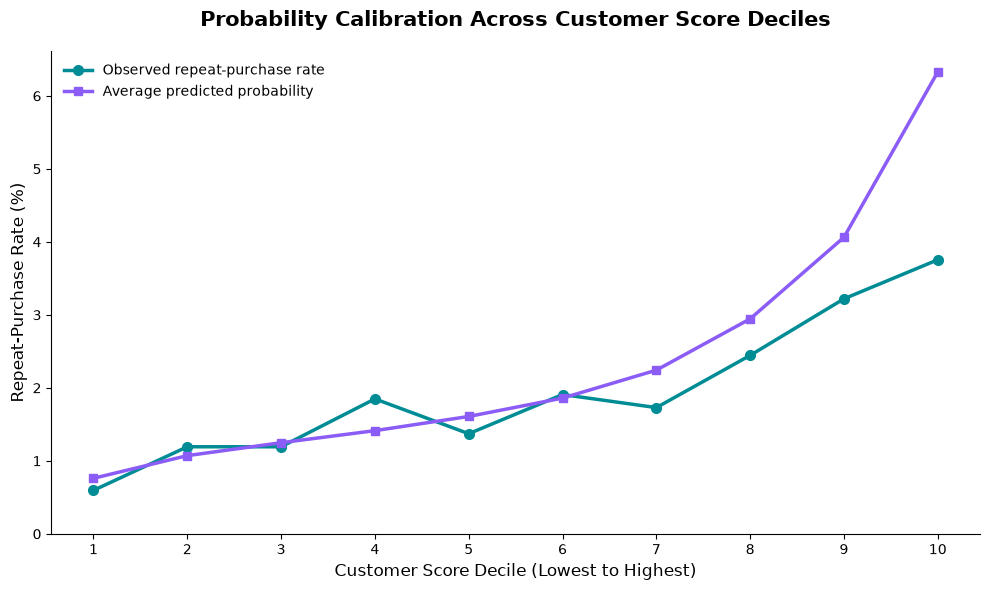

In [14]:
# Visualise probability calibration

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

# Observed repeat-purchase rates
ax.plot(
    calibration_summary["score_decile"],
    calibration_summary["observed_pct"],
    color="#008C95",
    marker="o",
    linewidth=2.5,
    markersize=7,
    label="Observed repeat-purchase rate"
)

# Model-predicted probabilities
ax.plot(
    calibration_summary["score_decile"],
    calibration_summary["predicted_pct"],
    color="#8B5CF6",
    marker="s",
    linewidth=2.5,
    markersize=6,
    label="Average predicted probability"
)

# Chart formatting
ax.set_title(
    "Probability Calibration Across Customer Score Deciles",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Customer Score Decile (Lowest to Highest)", fontsize=12)
ax.set_ylabel("Repeat-Purchase Rate (%)", fontsize=12)

ax.set_xticks(range(1, 11))
ax.set_ylim(bottom=0)

ax.legend(frameon=False, loc="upper left")

# Clean visual style
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

### Probability Calibration: Results and Interpretation

**Objective**

Evaluate whether the selected Logistic Regression model's predicted repeat-purchase probabilities reflect observed customer outcomes.

#### Validation Population

- Customers evaluated: 16,772
- Observed repeat purchasers: 323
- Observed repeat-purchase rate: 1.93%
- Average predicted probability: 2.35%

#### Key Findings

The model demonstrates some ability to rank customers by repeat-purchase likelihood, with observed repeat rates increasing from 0.60% in the lowest-scoring decile to 3.75% in the highest-scoring decile.

However, predicted probabilities do not consistently match observed outcomes.

In the highest-scoring decile, the model predicts an average repeat-purchase probability of 6.33%, compared with an observed rate of 3.75%. This represents an overestimate of 2.58 percentage points.

The discrepancy is particularly relevant because the highest-scoring customers would be prioritised in a model-based targeting strategy.

#### Business Interpretation

The model may be useful for ranking customers according to their relative likelihood of returning.

However, its predicted probabilities should not be treated as precise estimates of future repeat-purchase rates, particularly for high-scoring customer groups.

Decisions requiring reliable absolute probabilities, such as expected revenue forecasts or campaign profitability estimates, would require further validation and potentially improved calibration.

#### Methodological Limitations

- Calibration was evaluated on historical validation data.
- Each decile contains approximately 1,677 customers, but observed positive outcomes remain relatively rare.
- The Brier Score of 0.0189 should be interpreted alongside the low overall repeat-purchase rate.
- Earlier chronological feasibility checks found insufficient fully matured post-training observations for a reliable additional calibration stage.
- No additional probability calibrator has been fitted.
- The reserved test dataset remains untouched.

**Next step:** Assess whether model discrimination, ranking lift and probability reliability remain stable across validation months.

In [6]:
#  Evaluate monthly model stability

# Assemble validation results by purchase month
temporal_validation = pd.DataFrame({
    "month": customer_features.loc[
        X_validation.index,
        "order_purchase_timestamp"
    ].dt.to_period("M").astype(str).to_numpy(),

    "actual_return": y_validation.to_numpy(),

    "predicted_probability": validation_scores
})

# Calculate monthly performance
monthly_results = []

for month, group in temporal_validation.groupby("month"):

    actual = group["actual_return"]
    scores = group["predicted_probability"]

    observed_rate = actual.mean()
    predicted_rate = scores.mean()

    ap = average_precision_score(actual, scores)

    monthly_results.append({
        "month": month,
        "customers": len(group),
        "repeat_purchasers": int(actual.sum()),
        "observed_rate_pct": observed_rate * 100,
        "predicted_rate_pct": predicted_rate * 100,
        "average_precision": ap,
        "ap_lift": ap / observed_rate,
        "roc_auc": roc_auc_score(actual, scores),
        "prediction_gap_pp": (
            predicted_rate - observed_rate
        ) * 100
    })

monthly_stability = pd.DataFrame(monthly_results)

print("Monthly Model Stability")
print("-" * 45)

print(
    monthly_stability.round(4).to_string(index=False)
)

print("\nTotal validation customers:",
      monthly_stability["customers"].sum())

print("Total repeat purchasers:",
      monthly_stability["repeat_purchasers"].sum())

Monthly Model Stability
---------------------------------------------
  month  customers  repeat_purchasers  observed_rate_pct  predicted_rate_pct  average_precision  ap_lift  roc_auc  prediction_gap_pp
2017-10       4353                 98             2.2513              2.2932             0.0556   2.4676   0.6642             0.0419
2017-11       7114                150             2.1085              2.4443             0.0384   1.8200   0.6239             0.3358
2017-12       5305                 75             1.4138              2.2832             0.0252   1.7807   0.5958             0.8695

Total validation customers: 16772
Total repeat purchasers: 323


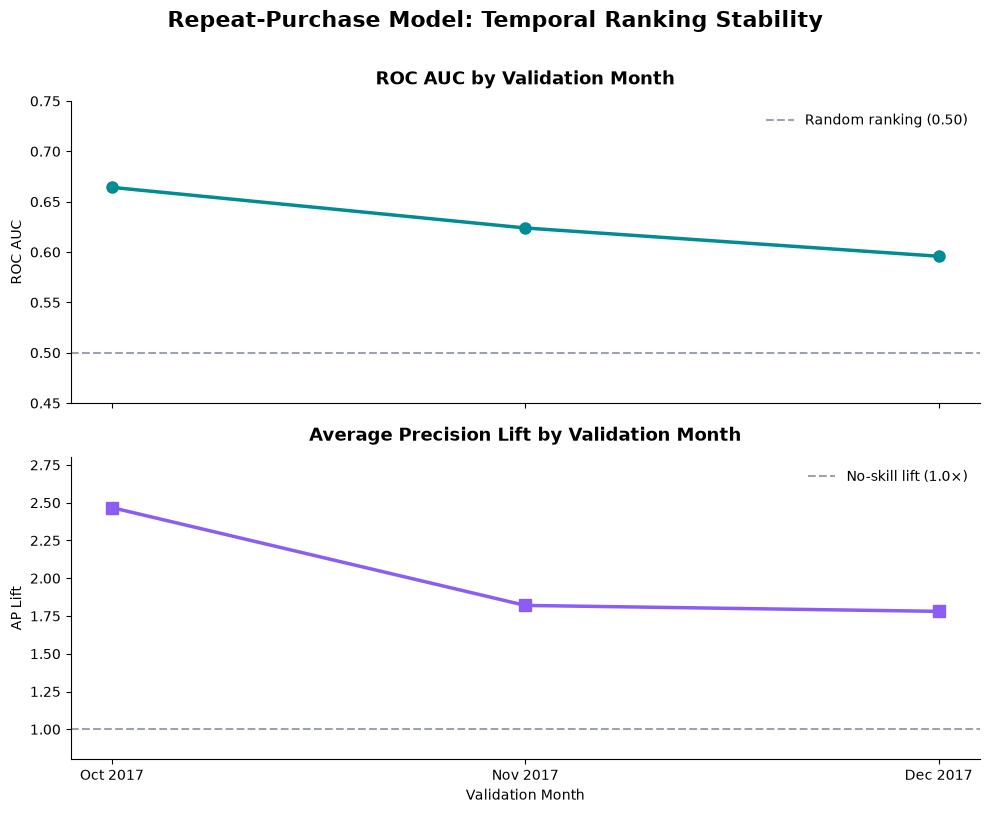

In [7]:
# Visualise monthly ranking stability

import matplotlib.pyplot as plt

months = ["Oct 2017", "Nov 2017", "Dec 2017"]

fig, axes = plt.subplots(
    2, 1,
    figsize=(10, 8),
    sharex=True
)

# Panel 1: ROC AUC
axes[0].plot(
    months,
    monthly_stability["roc_auc"],
    color="#008C95",
    marker="o",
    linewidth=2.5,
    markersize=8
)

axes[0].axhline(
    0.5,
    color="#9CA3AF",
    linestyle="--",
    linewidth=1.5,
    label="Random ranking (0.50)"
)

axes[0].set_title(
    "ROC AUC by Validation Month",
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[0].set_ylabel("ROC AUC")
axes[0].set_ylim(0.45, 0.75)
axes[0].legend(frameon=False)

# Panel 2: Average Precision Lift
axes[1].plot(
    months,
    monthly_stability["ap_lift"],
    color="#8B5CF6",
    marker="s",
    linewidth=2.5,
    markersize=8
)

axes[1].axhline(
    1.0,
    color="#9CA3AF",
    linestyle="--",
    linewidth=1.5,
    label="No-skill lift (1.0×)"
)

axes[1].set_title(
    "Average Precision Lift by Validation Month",
    fontsize=13,
    fontweight="bold",
    pad=12
)

axes[1].set_ylabel("AP Lift")
axes[1].set_xlabel("Validation Month")
axes[1].set_ylim(0.8, 2.8)
axes[1].legend(frameon=False)

# Clean visual styling
for ax in axes:
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Repeat-Purchase Model: Temporal Ranking Stability",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

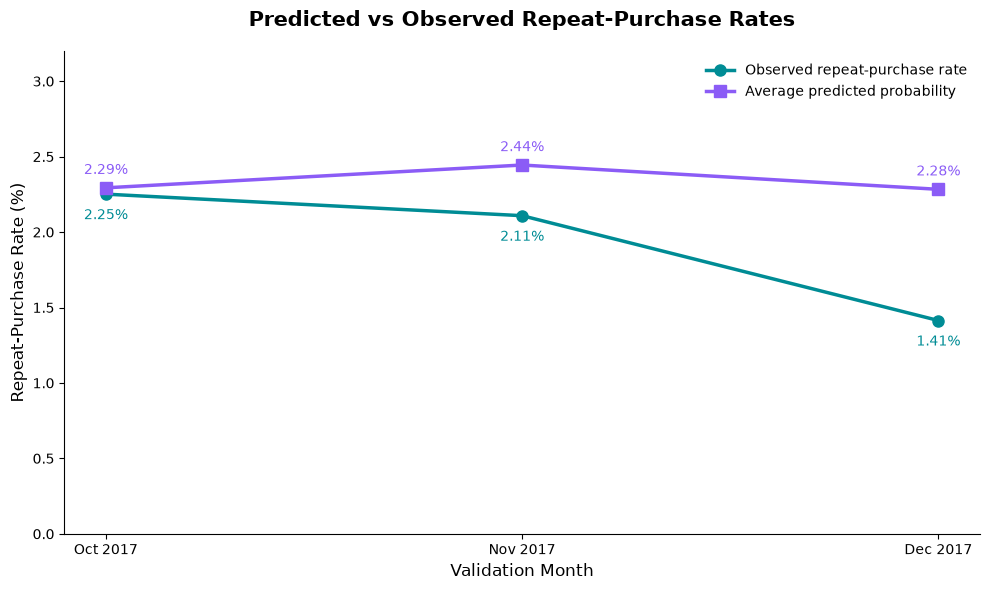

In [15]:
# Visualise monthly probability reliability

import matplotlib.pyplot as plt

months = ["Oct 2017", "Nov 2017", "Dec 2017"]

fig, ax = plt.subplots(figsize=(10, 6))

# Observed repeat-purchase rates
ax.plot(
    months,
    monthly_stability["observed_rate_pct"],
    color="#008C95",
    marker="o",
    linewidth=2.5,
    markersize=8,
    label="Observed repeat-purchase rate"
)

# Average predicted probabilities
ax.plot(
    months,
    monthly_stability["predicted_rate_pct"],
    color="#8B5CF6",
    marker="s",
    linewidth=2.5,
    markersize=8,
    label="Average predicted probability"
)

# Label each point
for i, row in monthly_stability.reset_index(drop=True).iterrows():

    ax.annotate(
        f"{row['observed_rate_pct']:.2f}%",
        (i, row["observed_rate_pct"]),
        xytext=(0, -18),
        textcoords="offset points",
        ha="center",
        color="#008C95",
        fontsize=10
    )

    ax.annotate(
        f"{row['predicted_rate_pct']:.2f}%",
        (i, row["predicted_rate_pct"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center",
        color="#8B5CF6",
        fontsize=10
    )

ax.set_title(
    "Predicted vs Observed Repeat-Purchase Rates",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Validation Month", fontsize=12)
ax.set_ylabel("Repeat-Purchase Rate (%)", fontsize=12)

ax.set_ylim(0, 3.2)
ax.legend(frameon=False, loc="upper right")

# Clean visual style
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

## Temporal Stability and Model Reliability

### Objective

Assess whether the selected Logistic Regression model maintains consistent ranking performance and probability reliability across historical validation cohorts.

The evaluation covers October, November and December 2017.

### Monthly Validation Results

| Metric | October | November | December |
|---|---:|---:|---:|
| Customers | 4,353 | 7,114 | 5,305 |
| Repeat purchasers | 98 | 150 | 75 |
| ROC AUC | 0.6642 | 0.6239 | 0.5958 |
| Average Precision | 0.0556 | 0.0384 | 0.0252 |
| AP Lift | 2.47× | 1.82× | 1.78× |
| Observed repeat rate | 2.25% | 2.11% | 1.41% |
| Predicted repeat rate | 2.29% | 2.44% | 2.28% |

### Key Findings

**Declining ranking performance**

Both ROC AUC and Average Precision Lift decreased between October and December, suggesting weaker model discrimination in later validation cohorts.

**Changing customer outcomes**

The observed repeat-purchase rate declined from 2.25% in October to 1.41% in December.

**Increasing probability overestimation**

Average predicted probabilities remained relatively stable despite declining observed repeat-purchase rates.

The prediction gap increased from approximately 0.04 percentage points in October to 0.87 percentage points in December.

### Business Implications

The model demonstrates some ability to rank customers by repeat-purchase likelihood, but its performance varies across historical periods.

A business using this model would need to monitor ranking quality, observed repeat-purchase rates and probability calibration over time.

Its predicted probabilities should not be used as precise forecasts of customer behaviour without further reliability assessment.

### Limitations

- The analysis covers only three validation months.
- Monthly repeat-purchaser counts are relatively small.
- Changes in customer composition, product preferences and seasonal behaviour may contribute to the observed differences.
- The analysis is descriptive and does not establish the cause of performance changes.
- Historical availability of first-order features requires further verification.
- The reserved test dataset remains untouched.

### Next Steps

Investigate whether changing customer composition contributes to temporal differences, review outstanding feature-availability assumptions and complete the model's final reliability assessment before holdout evaluation.

In [9]:
# Audit model feature availability

feature_availability = pd.DataFrame({
    "feature": list(selected_model.feature_names_in_),

    "availability_assumption": [
        "Available from customer checkout details",
        "Available at first purchase",
        "Available at first purchase",
        "Available at first purchase",
        "Available from first-order items",
        "Available from first-order items",
        "Available from first-order items",
        "Available from first-order shipping details",
        "Available from first-order product information"
    ]
})

print("Model Feature Availability Audit")
print("-" * 55)

print(feature_availability.to_string(index=False))

print(
    "\nTotal features reviewed:",
    len(feature_availability)
)

Model Feature Availability Audit
-------------------------------------------------------
                     feature                        availability_assumption
              customer_state       Available from customer checkout details
              purchase_month                    Available at first purchase
        purchase_day_of_week                    Available at first purchase
               purchase_hour                    Available at first purchase
      first_order_item_count               Available from first-order items
   first_order_product_count               Available from first-order items
      first_order_item_value               Available from first-order items
   first_order_freight_value    Available from first-order shipping details
first_order_primary_category Available from first-order product information

Total features reviewed: 9


In [16]:
# Evaluate customer targeting effectiveness

targeting_results = []

# Evaluate different targeting proportions
for target_pct in [10, 20, 30, 50]:

    # Select the highest-scoring customers
    n_targeted = int(np.ceil(len(validation_scores) * target_pct / 100))

    ranked_customers = pd.DataFrame({
        "actual": y_validation.to_numpy(),
        "predicted_probability": validation_scores
    }).sort_values(
        "predicted_probability",
        ascending=False,
        kind="stable"
    )

    targeted = ranked_customers.head(n_targeted)

    # Calculate targeting performance
    captured_repeaters = int(targeted["actual"].sum())
    total_repeaters = int(y_validation.sum())

    capture_rate = captured_repeaters / total_repeaters * 100
    targeted_repeat_rate = targeted["actual"].mean() * 100
    overall_repeat_rate = y_validation.mean() * 100

    lift = targeted_repeat_rate / overall_repeat_rate

    targeting_results.append({
        "Targeted (%)": target_pct,
        "Customers Targeted": n_targeted,
        "Repeat Purchasers Captured": captured_repeaters,
        "Capture Rate (%)": round(capture_rate, 2),
        "Targeted Repeat Rate (%)": round(targeted_repeat_rate, 2),
        "Lift": round(lift, 2)
    })

targeting_summary = pd.DataFrame(targeting_results)

print("Customer Targeting Effectiveness")
print("-" * 60)

display(targeting_summary)

Customer Targeting Effectiveness
------------------------------------------------------------


,Targeted (%),Customers Targeted,Repeat Purchasers Captured,Capture Rate (%),Targeted Repeat Rate (%),Lift
0,10,1678,63,19.50,3.75,1.95
1,20,3355,117,36.22,3.49,1.81
2,30,5032,158,48.92,3.14,1.63
3,50,8386,219,67.80,2.61,1.36


In [17]:
# Check whether reserved test customers have complete observation windows

# Identify the observed end of the available order history
print("Maximum first-purchase timestamp in features:")
print(customer_features["order_purchase_timestamp"].max())

# Inspect the existing reserved test period
test_start = pd.Timestamp("2018-04-01")

potential_test_customers = customer_features[
    customer_features["order_purchase_timestamp"] >= test_start
].copy()

print(
    "\nPotential test customers:",
    len(potential_test_customers)
)

print(
    "Latest potential test purchase:",
    potential_test_customers[
        "order_purchase_timestamp"
    ].max()
)

Maximum first-purchase timestamp in features:
2018-06-02 23:42:33

Potential test customers: 13649
Latest potential test purchase: 2018-06-02 23:42:33


In [18]:
# Validate reserved test eligibility

observation_cutoff = pd.Timestamp("2018-08-31 23:59:59")
prediction_window = pd.Timedelta(days=60)
delivery_buffer = pd.Timedelta(days=30)

test_start = pd.Timestamp("2018-04-01")

latest_eligible_test_date = (
    observation_cutoff
    - prediction_window
    - delivery_buffer
)

# Identify potential holdout customers
potential_test_mask = (
    customer_features["order_purchase_timestamp"] >= test_start
)

# Apply the original observation-window requirement
eligible_test_mask = (
    potential_test_mask
    & (
        customer_features["order_purchase_timestamp"]
        <= latest_eligible_test_date
    )
)

print("Potential test customers:", potential_test_mask.sum())

print("Eligible test customers:", eligible_test_mask.sum())

print(
    "Customers excluded by observation window:",
    potential_test_mask.sum() - eligible_test_mask.sum()
)

print(
    "Latest eligible first-purchase date:",
    latest_eligible_test_date
)

print(
    "Latest actual eligible first purchase:",
    customer_features.loc[
        eligible_test_mask,
        "order_purchase_timestamp"
    ].max()
)

Potential test customers: 13649
Eligible test customers: 13649
Customers excluded by observation window: 0
Latest eligible first-purchase date: 2018-06-02 23:59:59
Latest actual eligible first purchase: 2018-06-02 23:42:33


In [19]:
# Prepare the reserved holdout evaluation dataset

# Retrieve the exact features used by the saved model
model_features = list(selected_model.feature_names_in_)

# Apply the same complete-case requirement as validation
test_complete_mask = (
    customer_features[model_features]
    .notna()
    .all(axis=1)
)

# Combine eligibility and feature completeness
matched_test_mask = eligible_test_mask & test_complete_mask

# Prepare final holdout features and target
X_test = customer_features.loc[
    matched_test_mask, model_features
].copy()

y_test = customer_features.loc[
    matched_test_mask, "repeat_purchase_60d"
].copy()

# Validate the final holdout population
print("Eligible test customers:", int(eligible_test_mask.sum()))

print("Final model test customers:", len(X_test))

print(
    "Excluded due to missing features:",
    int(eligible_test_mask.sum()) - len(X_test)
)

print("Repeat purchasers:", int(y_test.sum()))

print(
    "Observed repeat-purchase rate:",
    f"{y_test.mean():.4%}"
)

print(
    "Missing model feature values:",
    int(X_test.isna().sum().sum())
)

print(
    "Duplicate customers:",
    int(
        customer_features.loc[
            matched_test_mask, "customer_unique_id"
        ].duplicated().sum()
    )
)

Eligible test customers: 13649
Final model test customers: 13523
Excluded due to missing features: 126
Repeat purchasers: 197
Observed repeat-purchase rate: 1.4568%
Missing model feature values: 0
Duplicate customers: 0


In [20]:
# Final holdout evaluation of the saved Logistic Regression model

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

# Generate predictions without retraining the model
test_scores = selected_model.predict_proba(X_test)[:, 1]

# Calculate holdout performance
test_metrics = {
    "Average Precision": average_precision_score(
        y_test, test_scores
    ),
    "ROC AUC": roc_auc_score(
        y_test, test_scores
    ),
    "Brier Score": brier_score_loss(
        y_test, test_scores
    ),
    "Log Loss": log_loss(
        y_test, test_scores
    )
}

# Compare validation and holdout performance
performance_comparison = pd.DataFrame({
    "Validation": validation_metrics,
    "Holdout Test": test_metrics
})

print("Validation vs Final Holdout Performance")
print("-" * 55)

display(performance_comparison.round(4))

print(
    "\nValidation repeat-purchase rate:",
    f"{y_validation.mean():.4%}"
)

print(
    "Holdout repeat-purchase rate:",
    f"{y_test.mean():.4%}"
)

print(
    "\nHoldout average predicted probability:",
    f"{test_scores.mean():.4%}"
)

Validation vs Final Holdout Performance
-------------------------------------------------------


,Validation,Holdout Test
Average Precision,0.0375,0.0281
ROC AUC,0.6305,0.5753
Brier Score,0.0189,0.0145
Log Loss,0.0938,0.0777



Validation repeat-purchase rate: 1.9258%
Holdout repeat-purchase rate: 1.4568%

Holdout average predicted probability: 2.2204%


In [22]:
# Compare final holdout performance against the training-rate baseline

# Use the training repeat-purchase rate established in Notebook 03
training_repeat_rate = 0.021920

holdout_baseline_scores = np.full(
    len(y_test),
    training_repeat_rate
)

holdout_baseline_metrics = {
    "Average Precision": average_precision_score(
        y_test, holdout_baseline_scores
    ),
    "ROC AUC": roc_auc_score(
        y_test, holdout_baseline_scores
    ),
    "Brier Score": brier_score_loss(
        y_test, holdout_baseline_scores
    ),
    "Log Loss": log_loss(
        y_test, holdout_baseline_scores
    )
}

holdout_comparison = pd.DataFrame({
    "No-Skill Baseline": holdout_baseline_metrics,
    "Logistic Regression": test_metrics
})

print("Final Holdout: Model vs No-Skill Baseline")
print("-" * 55)

display(holdout_comparison.round(5))

Final Holdout: Model vs No-Skill Baseline
-------------------------------------------------------


,No-Skill Baseline,Logistic Regression
Average Precision,0.01457,0.02813
ROC AUC,0.50000,0.57529
Brier Score,0.01441,0.01448
Log Loss,0.07750,0.07770


## Final Model Evaluation and Reliability Assessment

### Objective

Evaluate the selected Logistic Regression model's ability to predict 60-day repeat purchases using first-purchase information, with particular attention to discrimination, probability reliability, temporal stability and generalisation.

### Final Holdout Results

The reserved holdout evaluation included 13,523 customers, of whom 197 made a qualifying repeat purchase within 60 days.

| Metric | Logistic Regression | No-Skill Baseline |
|---|---:|---:|
| Average Precision | 0.02813 | 0.01457 |
| ROC AUC | 0.57529 | 0.50000 |
| Brier Score | 0.01448 | 0.01441 |
| Log Loss | 0.07770 | 0.07750 |

The model achieved approximately 1.93× Average Precision lift over the no-skill benchmark, indicating some ability to rank customers by repeat-purchase likelihood.

However, its probability-based error metrics were slightly worse than the constant-probability benchmark.

### Key Findings

**Predictive ranking:** The model identifies some repeat-purchase signal, but discriminatory performance is modest and weaker than during validation.

**Probability reliability:** The average predicted repeat-purchase probability was 2.2204%, compared with an observed rate of 1.4568%, indicating systematic overprediction at the population level.

**Temporal generalisation:** The decline in ROC AUC from 0.6305 during validation to 0.5753 on holdout is consistent with the earlier temporal-stability concerns.

**Customer coverage:** The evaluation uses complete-case records. Customers with incomplete model features are excluded, limiting coverage of the full eligible population.

### Conclusion

The Logistic Regression model provides a reproducible baseline and some customer-ranking value but does not currently demonstrate sufficient probability reliability for deployment as an automated retention decision system.

Future development should prioritise improved feature coverage, stronger predictive models and probability calibration, evaluated using appropriately separated development data.

The reserved holdout findings will be retained as the final independent assessment of this baseline model.

### Next Development Stage

Progress to model explainability and structured model improvement while preserving the existing benchmark and avoiding further model selection based on the reserved holdout.